# Teaching NanoGPT to Do Math with DPO: working out the steps

SC3000/CZ3005 Assignment 1

**Team and contributions:** *(to fill in before submission: team name, members, and what each member did.)*

## Overview

The model is a small character-level NanoGPT (8.8M parameters) pretrained on question-answer chat data. Before fine-tuning it answers arithmetic questions with "Sorry, I don't know." We fine-tune it with DPO (Direct Preference Optimization): for each question the training data holds a preferred reply (the *positive*) and a rejected reply (the *negative*), and the loss makes the positive more likely than the negative.

In our first attempt (an earlier notebook, not part of this submission, whose results we quote here), the positives stated the answer first, like the sample file: `86*83=? The answer is 7138 because 86*83 equals 7138.` That model got all additions and subtractions among our test questions (the same 600 as in this notebook) right and 80% of the divisions, but **only a third of the multiplications**, because it had to write all digits of a product in one go. (Here *multiplications* are the questions whose answer is a product, `a*b=?` and `x/a=b,x=?`, and *divisions* those whose answer is a quotient, such as `a/b=?` and `x*a=b,x=?`.) This notebook makes two main changes:

1. **The positive works the answer out in steps** before stating it: `86*83=? 86*80 is 6880, 86*3 is 258, 6880+258 is 7138, so the answer is 7138.` Each step is an easier calculation, and the model can read its earlier results while writing the next one (Task 1, following Lee et al., 2024).
2. **The SFT (supervised fine-tuning) part of the loss has weight 1 instead of 0.1** (Step 7, following Pang et al., 2024).

We also train for 20 epochs instead of 12 and lower the learning rate once per epoch instead of after every batch (Steps 2 and 6). The longer training **explains only part of the gain** over our first attempt (82.3%): after 12 epochs the accuracy was already 93.0% (Step 7).

Both main changes, the steps and SFT weight 1, come from small experiments on multiplication questions, described at the end of the notebook. One more idea we tried there, using the model's own wrong answers as negatives (after Pang et al., 2024), made training fail or take twice as long and is not used.

**Result.** The final model answers **588 of our 600 test questions correctly (98.0%)**, against 82.3% for our first attempt, and all eight questions of the template's test set (Step 8). All multiplications are now right; the 12 remaining errors are all divisions.

| Task | Where |
|---|---|
| Task 1: build positive-negative pairs | the "Task 1" section after Step 4 |
| Task 2: fine-tune with DPO | Steps 5–7 |
| Task 3: test the fine-tuned model | Step 8 |
| Task 4: explanation and analysis | the text cells |

**How to run.** Put this folder inside the course repository `NanoGPT-Math`, next to `sft/` and `model.py`, because the code uses relative paths such as `../sft/gpt.pt` and `../model.py`. Then run the cells from top to bottom. On one NVIDIA Tesla V100 GPU the whole notebook took about 2 h 20 min, almost all of it in two cells: about 69 min to generate the negatives in Task 1 and about 69 min for Step 7 (training plus a test after every epoch). Running the cell that calls `generate_negatives_from_pretrained` overwrites `pos_neg_pairs.json`, and Step 7 overwrites `dpo.pt` after every epoch, so **keep a copy of the submitted files** before running them again.

**To test the submitted `dpo.pt` only** (without rebuilding the data or retraining): run Steps 1–4 and the Task 1 code cells except the last one (the one that calls `generate_negatives_from_pretrained`), skip Steps 5–7, then run Step 8.

**Changes to the provided template:**
- Step 1 installs packages with `%pip` instead of `!pip`.
- Step 2 also uses Apple's GPU (`mps`) and prints the device, drops the `CUDA_VISIBLE_DEVICES = "1"` line and the second `import random`, imports `re` and `Counter`, sets `max_length = 104`, uses learning rate `1e-3` and 20 epochs instead of `1e-4` and 5, and adds one setting, `sft_weight`.
- Step 5 loads `./pos_neg_pairs.json`, the file Task 1 writes, instead of the `./data/pos_neg_pairs.json` in the template comment.
- Step 6 uses AdamW and lowers the learning rate along a cosine curve, once per epoch.
- Step 7 writes the loss as its two parts with SFT weight 1 instead of 0.1, clips the gradients, gives the progress bar its length and shows the loss on it, prints the "Saved checkpoint" message in the line after each epoch, and checks the accuracy on the test questions after every epoch.
- Step 8 completes the test loop, uses `.to(device)` instead of `.cuda()`, loads `./dpo.pt`, the file Step 7 saves, instead of the template's `../dpo/dpo.pt`, reads the weights from `model_state_dict` directly, and marks each reply as right or wrong.

## Setup (Steps 1–4)

### Step 1: Install necessary packages

`%pip` installs into the environment of the running kernel. `!pip` runs whichever `pip` comes first on the shell's PATH, which can belong to a different Python. Only `torch`, `matplotlib` and `tqdm` are imported below; the other packages are kept from the template.

In [1]:
%pip install matplotlib
%pip install torch numpy transformers datasets tiktoken wandb tqdm

### Step 2: Package imports and configuration

Changes from the template:
- **Device.** The template only checks for CUDA. We also use Apple's GPU (`mps`) when there is one, fall back to the CPU otherwise, and print which device is used.
- **`CUDA_VISIBLE_DEVICES = "1"` removed.** That line hides every GPU except the second one. On a machine with a single GPU, PyTorch would then see no GPU at all and silently train on the CPU.
- **`max_length = 104` instead of 64.** The steps make the positives longer: the longest is 102 characters with the 4 newlines (printed in Task 1). `pad_or_truncate` keeps the *last* `max_length` characters, so a longer sample would lose its start, the question.
- **Learning rate `1e-3` instead of `1e-4`, and 20 epochs instead of 5.** In a one-epoch trial during our first attempt (answer-first positives, not shown here), the template's `1e-4` taught the model the sentence pattern, but only 1.7% of its answers to our test questions were right; we did not try `1e-4` for longer. With `1e-3` and 12 epochs, our first attempt's accuracy stayed low for two epochs and then jumped (3.0%, 7.3% and 35.3% after epochs 1–3). After one epoch the two learning rates gave about the same accuracy (1.7% and 3.0%), so this does not show that `1e-3` is better; we raised the learning rate because learning the arithmetic is the slow part. In our experiments on multiplication questions (end of the notebook), the accuracy was still rising after 12 epochs, so we train for 20.
- **`sft_weight = 1.0`** is new: the weight of the SFT term in the loss, which the template sets to 0.1 (explained in Step 7).
- `re` and `Counter` are imported for Task 1 and Step 8, and the template's second `import random` is dropped.

The other settings are the template's: `beta = 0.5`, batch size 64, and the sampling settings for `gpt.generate` (temperature 0.8, top_k 200, at most 200 new characters).

The tokenizer works on single characters: `meta.pkl` maps each of the 74 characters to an id. The newline character has id 0, which is also used for padding, and `.` has id 7. `gpt.generate` in `model.py` stops at either of these two.

In [2]:
import sys
import os
sys.path.append(os.path.abspath(".."))
import torch
import torch.nn as nn
import torch.nn.functional as F
import random
import pickle
from model import GPT, GPTConfig
from tqdm import tqdm
import time
import json
import re
from collections import Counter
import matplotlib.pyplot as plt
# Configuration
beta = 0.5
if torch.cuda.is_available():
    device = 'cuda'
elif torch.backends.mps.is_available():
    device = 'mps'
else:
    device = 'cpu'
print("Device:", device)
base_lr = 1e-3
epochs = 20
batch_size = 64
max_length = 104
num_samples = 1
max_new_tokens = 200
temperature = 0.8
top_k = 200
sft_weight = 1.0  # weight of the SFT term in the loss; the template uses 0.1 (see Step 7)
# tokenizer
with open("../sft/meta.pkl", "rb") as f:
    meta = pickle.load(f)
stoi, itos = meta["stoi"], meta["itos"]
def encode(s): return [stoi[c] for c in s]
def decode(l): return ''.join([itos[i] for i in l])

Device: cuda


### Step 3: Define helper functions

These three functions come with the template:
- `compute_logprob(input_ids)` runs the model on each sequence and returns the **average log-probability per character**, leaving out padding (id 0). For a batch of `B` sequences it returns a tensor of shape `B`.
- `pad_or_truncate(seq, max_length)` pads a sequence with id 0 up to `max_length`. A longer sequence keeps only its last `max_length` ids.
- `get_batches(lines, batch_size)` shuffles the pairs, appends 4 newlines to each negative and positive, encodes and pads them, and yields `(neg_tensor, pos_tensor)`, each of shape `batch_size × max_length`. The last incomplete batch is dropped.

Because the newline is id 0, the 4 newlines appended in `get_batches` are treated as padding and never scored. The model therefore learns to end a reply with `.`, which is also where `gpt.generate` stops.

In [3]:
def compute_logprob(input_ids):
    inputs = input_ids[:, :-1]
    targets = input_ids[:, 1:]
    logits, _ = gpt(inputs, full_seq=True)
    B, T, V = logits.size()
    logits_flat = logits.reshape(-1, V)
    targets_flat = targets.reshape(-1)
    loss = F.cross_entropy(logits_flat, targets_flat, ignore_index=0, reduction='none')
    loss = loss.reshape(B, T)
    attention_mask = (targets != 0).float()
    loss = (loss * attention_mask).sum(dim=1) / attention_mask.sum(dim=1)
    return -loss 

def pad_or_truncate(seq, max_length):
    return seq[-max_length:] if len(seq) > max_length else seq + [0] * (max_length - len(seq))

def get_batches(lines, batch_size):
    random.shuffle(lines)
    #for l in lines:
    #  print(l[1])
    for i in range(0, len(lines), batch_size):
        batch = lines[i:i+batch_size]
        if len(batch) < batch_size:
            continue
        neg_inputs = [pad_or_truncate(encode(p['negative'] + '\n\n\n\n'), max_length) for p in batch]
        pos_inputs = [pad_or_truncate(encode(p['positive'] + '\n\n\n\n'), max_length) for p in batch]
        neg_tensor = torch.tensor(neg_inputs, dtype=torch.long, device=device)
        pos_tensor = torch.tensor(pos_inputs, dtype=torch.long, device=device)
        yield neg_tensor, pos_tensor

### Step 4: Load the pretrained NanoGPT model

This loads `sft/gpt.pt`: 6 layers, 6 attention heads, 348-dimensional embeddings, a context of 256 characters and a 74-character vocabulary, 8.8M parameters in total. The `_orig_mod.` prefix that `torch.compile` adds to the weight names is removed before loading. The model is left in training mode, so dropout (p = 0.2) is on.

In [4]:
ckpt = torch.load("../sft/gpt.pt", map_location=device)
gptconf = GPTConfig(**ckpt['model_args'])
gpt = GPT(gptconf)
state_dict = ckpt['model']
unwanted_prefix = '_orig_mod.'
for k in list(state_dict.keys()):
    if k.startswith(unwanted_prefix):
        state_dict[k[len(unwanted_prefix):]] = state_dict.pop(k)
gpt.load_state_dict(state_dict)
gpt.to(device).train()

GPT(
  (transformer): ModuleDict(
    (wte): Embedding(74, 348)
    (wpe): Embedding(256, 348)
    (drop): Dropout(p=0.2, inplace=False)
    (h): ModuleList(
      (0-5): 6 x Block(
        (ln_1): LayerNorm()
        (attn): CausalSelfAttention(
          (c_attn): Linear(in_features=348, out_features=1044, bias=False)
          (c_proj): Linear(in_features=348, out_features=348, bias=False)
          (attn_dropout): Dropout(p=0.2, inplace=False)
          (resid_dropout): Dropout(p=0.2, inplace=False)
        )
        (ln_2): LayerNorm()
        (mlp): MLP(
          (c_fc): Linear(in_features=348, out_features=1392, bias=False)
          (gelu): GELU(approximate='none')
          (c_proj): Linear(in_features=1392, out_features=348, bias=False)
          (dropout): Dropout(p=0.2, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm()
  )
  (lm_head): Linear(in_features=348, out_features=74, bias=False)
)

## Task 1: Build positive-negative data pairs

Task 1 has four code cells: the questions, the positives, the functions that let the model answer a question and check its reply, and the negatives. The last one writes all pairs to `./pos_neg_pairs.json`.

**Questions.** These are the same questions as in our first attempt.
- There are 12 types: the four operations asked directly (`a+b=?`, `a-b=?`, `a*b=?`, `a/b=?`), and each operation as an equation with `x` on the left (`x+a=b,x=?`) or on the right (`a+x=b,x=?`).
- For each type we take every pair of numbers from 0–100 and calculate the third number from them, so the answer is always a whole number.
- We split the questions in the following way: for each type, the questions are shuffled, the first 50 are **test questions**, and the next 9000 are used for training (`a-b=?` and `a-x=b,x=?` have only 5101 left, because no negative numbers are allowed). The total number of questions used for training is 100,202. We want to emphasize that we designed the test set this way, **instead of only testing the model on the 8 questions in the template**, to ensure a fairer comparison of the model's ability.

In [5]:
random.seed(0)
torch.manual_seed(0)
numbers = range(0, 101)
train_per_type = 9000  # training questions per type (a-b=? and a-x=b,x=? have fewer)
test_per_type = 50  # questions per type kept out of training, used as test questions
data_path = "./pos_neg_pairs.json"

# The 12 question types. Each function takes two numbers from 0..100 and returns
# (question, answer, calculation), where `calculation` is what has to be worked out
# to get the answer, or None when the pair is not allowed.
def add(a, b):
    return f"{a}+{b}=?", a + b, f"{a}+{b}"


def sub(a, b):
    if b > a:
        return None
    return f"{a}-{b}=?", a - b, f"{a}-{b}"


def multiply(a, b):
    return f"{a}*{b}=?", a * b, f"{a}*{b}"


def divide(divisor, quotient):
    if divisor <= 0:
        return None
    dividend = divisor * quotient
    return f"{dividend}/{divisor}=?", quotient, f"{dividend}/{divisor}"


def x_add(x, number):
    return f"x+{number}={x+number},x=?", x, f"{x+number}-{number}"


def add_x(x, number):
    return f"{number}+x={number+x},x=?", x, f"{number+x}-{number}"


def x_sub(number, result):
    x = number + result
    return f"x-{number}={result},x=?", x, f"{result}+{number}"


def sub_x(number, x):
    if x > number:
        return None
    result = number - x
    return f"{number}-x={result},x=?", x, f"{number}-{result}"


def x_multi(x, factor):
    if factor <= 0:
        return None
    product = x * factor
    return f"x*{factor}={product},x=?", x, f"{product}/{factor}"


def multi_x(x, factor):
    if factor <= 0:
        return None
    product = factor * x
    return f"{factor}*x={product},x=?", x, f"{product}/{factor}"


def x_divide(divisor, quotient):
    if divisor <= 0:
        return None
    x = divisor * quotient
    return f"x/{divisor}={quotient},x=?", x, f"{quotient}*{divisor}"


def divide_x(x, quotient):
    if x <= 0 or quotient <= 0:
        return None
    dividend = x * quotient
    return f"{dividend}/x={quotient},x=?", x, f"{dividend}/{quotient}"

question_types = [add, sub, multiply, divide, x_add, add_x, x_sub, sub_x, x_multi, multi_x, x_divide, divide_x]

def build_questions(f):
    result = []
    for p in numbers:
        for q in numbers:
            item = f(p, q)
            if item is not None:
                result.append(item)
    random.shuffle(result)
    return result

train_items = []  # (question, answer, calculation)
test_items = []  # the same, but never used for training
for q_type in question_types:
    items = build_questions(q_type)
    test_items += items[:test_per_type]
    train_items += items[test_per_type:test_per_type + train_per_type]
print("Number of training questions:", len(train_items))
print("Number of test questions:", len(test_items))

Number of training questions: 100202
Number of test questions: 600


**Positive samples.** We want the model to actually learn to reason, rather than just guess the answer from a huge amount of data, so each positive works the answer out in steps before giving it. This is because, during our research, we found that, according to Lee et al. (2024), **small transformers learn arithmetic much better** when the training text shows the intermediate steps. The positives are **generated entirely by our code, not by ChatGPT**. Each question function also returns the calculation that gives the answer (for `x/86=83,x=?` it is `83*86`), and `write_positive_sample` writes it out in steps. These are some examples of positive samples we generated:

| Question | Positive (after the question) |
|---|---|
| `86*83=?` | `86*80 is 6880, 86*3 is 258, 6880+258 is 7138, so the answer is 7138.` |
| `7138/86=?` | `86*80 is 6880, 7138-6880 is 258, 86*3 is 258, so the answer is 83.` |
| `x/86=83,x=?` | `x is 83*86, 83*80 is 6640, 83*6 is 498, 6640+498 is 7138, so the answer is 7138.` |
| `x+55=95,x=?` | `x is 95-55, 95-55 is 40, so the answer is 40.` |

In [6]:
def positive_sample_for_multi(a, b):
    ten, one = b // 10 * 10, b % 10  # 83 -> 80 and 3
    if ten == 0 or one == 0:  # b is a single digit, a multiple of 10, or 100
        return [f"{a}*{b} is {a * b}"]
    else:
        return [f"{a}*{ten} is {a * ten}",
            f"{a}*{one} is {a * one}",
            f"{a * ten}+{a * one} is {a * b}"]

def positive_sample_for_divide(a, b):
    res = a // b
    ten, one = res // 10 * 10, res % 10
    if ten == 0 or one == 0:
        return [f"{b}*{res} is {a}"]
    rest2 = a - b * ten
    return [f"{b}*{ten} is {b * ten}",
            f"{a}-{b * ten} is {rest2}",
            f"{b}*{one} is {rest2}"]

def write_positive_sample(qn, ans, cal):

    # "83*86" -> 83, "*", 86
    operator_at = -1
    for i, char in enumerate(cal):
        if char in "+-*/":
            operator_at = i
            break
    if operator_at < 0:
        raise ValueError(f"No operation in {cal!r}")

    a = int(cal[:operator_at])
    sign = cal[operator_at]
    b = int(cal[operator_at + 1:])
    if sign == "*":
        resp = positive_sample_for_multi(a, b)
    elif sign == "/":
        resp = positive_sample_for_divide(a, b)
    else:  # addition and subtraction take one step
        resp = [f"{cal} is {ans}"]
    if "x" in qn:  # first say which calculation gives x
        resp = [f"x is {cal}"] + resp
    # gpt.generate stops at ".", so the steps are joined with commas and only the end has a "."
    return f"{qn} {', '.join(resp)}, so the answer is {ans}."

qns = []
positives = []
for qn, ans, cal in train_items:
    qns.append(qn)
    positives.append(write_positive_sample(qn, ans, cal))

test_questions = []
for qn, ans, cal in test_items:
    test_questions.append(qn)

print("The positive for the first test question of each type:")
for qn, ans, cal in test_items[::test_per_type]:
    print(" ", write_positive_sample(qn, ans, cal))
longest = max(len(positive) for positive in positives) + 4  # get_batches adds 4 newlines
print(f"Longest positive: {longest} characters with the 4 newlines (max_length = {max_length})")


The positive for the first test question of each type:
  72+27=? 72+27 is 99, so the answer is 99.
  80-72=? 80-72 is 8, so the answer is 8.
  24*14=? 24*10 is 240, 24*4 is 96, 240+96 is 336, so the answer is 336.
  9000/100=? 100*90 is 9000, so the answer is 90.
  x+70=105,x=? x is 105-70, 105-70 is 35, so the answer is 35.
  86+x=157,x=? x is 157-86, 157-86 is 71, so the answer is 71.
  x-85=76,x=? x is 76+85, 76+85 is 161, so the answer is 161.
  92-x=86,x=? x is 92-86, 92-86 is 6, so the answer is 6.
  x*62=6076,x=? x is 6076/62, 62*90 is 5580, 6076-5580 is 496, 62*8 is 496, so the answer is 98.
  3*x=186,x=? x is 186/3, 3*60 is 180, 186-180 is 6, 3*2 is 6, so the answer is 62.
  x/76=11,x=? x is 11*76, 11*70 is 770, 11*6 is 66, 770+66 is 836, so the answer is 836.
  760/x=19,x=? x is 760/19, 19*40 is 760, so the answer is 40.
Longest positive: 102 characters with the 4 newlines (max_length = 104)


**Answering and checking.** This cell defines three functions, which are used again in Steps 7 and 8:
- `generate_reply` lets the model answer one question.
- `reply_is_correct` decides whether a reply is right. **Only the final answer is checked**, not the steps.
- `test` lets the model answer all the test questions and returns its accuracy.

In [7]:
def generate_reply(question):
    x = torch.tensor([encode(question)], dtype=torch.long, device=device)
    y, _ = gpt.generate(x, max_new_tokens, temperature=temperature, top_k=top_k)
    return decode(y[0].tolist())

def reply_is_correct(question, reply):
    # the reply starts with the question, so only search the part after it
    match = re.search(r"the answer is (\d+)", reply[len(question):])
    if match is None:
        return False
    answer = int(match.group(1))  # int, so a reply like "06" becomes 6
    if "x" in question:  # "x+55=95,x=?" -> 40+55 == 95
        left, right = question.split(",")[0].replace("x", str(answer)).split("=")
        try:
            return eval(left) == eval(right)
        except ZeroDivisionError:  # answering 0 to "84/x=7,x=?"
            return False
    return eval(question[:-2]) == answer  # "79-7=?" -> 79-7 == 72

def test():
    """Answer the test questions with the current model.
    Returns the fraction answered correctly and each question's reply."""
    gpt.eval()  # no dropout while answering
    reply_of = {}
    correct = 0
    for question in test_questions:
        reply_of[question] = generate_reply(question)
        if reply_is_correct(question, reply_of[question]):
            correct += 1
    gpt.train()
    return correct / len(test_questions), reply_of

**Negatives.** We use the original, pretrained NanoGPT model to answer all the training questions. Most of the answers are "Sorry, I don't know.", and we decided to use these original answers as the negative samples.

**Reproducibility.** The seed makes the questions and positives the same on every machine. The negatives also depend on the device's random number generator, so running this cell on another device gives slightly different negatives and overwrites `pos_neg_pairs.json`.

In [8]:
def generate_negatives_from_pretrained(question_list, preferred_replies, output_path):
    """Sample the old model's answers and save them beside the preferred answers."""
    started_at = time.time()
    rejected_replies = []

    # Sampling should use the same model settings for every question.
    gpt.eval()
    for qn in tqdm(question_list):
        reply = generate_reply(qn)
        rejected_replies.append(reply)
    gpt.train()
    # some metrics
    minutes_taken = (time.time() - started_at) / 60
    print(f"Generated {len(rejected_replies)} negatives in {minutes_taken:.1f} minutes")



    ### note that this part is only for metric, we want to make sure our 
    # negative samples generated correctly
    reply_counts = Counter()
    for qn, neg in zip(question_list, rejected_replies):
        answer_text = neg[len(qn):]
        reply_counts[answer_text] += 1
    print(f"{len(reply_counts)} different replies. The most common ones (without the question):")
    for reply_text, cnt in reply_counts.most_common(10):
        print(f"{cnt:8d}  {reply_text}")
    pairs = []
    for neg, pos in zip(rejected_replies, preferred_replies):
        pair = {"negative": neg, "positive": pos}
        pairs.append(pair)
    # we store all of the samples into a json
    with open(output_path, "w", encoding="utf-8") as pair_file:
        json.dump(pairs, pair_file, ensure_ascii=False, indent=1)
    print(f"Saved {len(pairs)} pairs to {output_path}")
    # for log only
    print("Some example pairs:")
    for pair in random.sample(pairs, 5):
        print(pair)


generate_negatives_from_pretrained(qns, positives, data_path)


100%|██████████| 100202/100202 [1:09:01<00:00, 24.19it/s]


Generated 100202 negatives in 69.0 minutes
831 different replies. The most common ones (without the question):
   64782   Sorry, I don't know.
   26599   Sory, I don't know.
    5815   I don't know.
     312   I Sorry, I don't know.
     217   Sorrry, I don't know.
     201   Se, I don't know.
     154   I Sory, I don't know.
     117   I PM
      96   Sery, I don't know.
      80   =? Sorry, I don't know.
Saved 100202 pairs to ./pos_neg_pairs.json
Some example pairs:
{'negative': "39*12=? Sorry, I don't know.", 'positive': '39*12=? 39*10 is 390, 39*2 is 78, 390+78 is 468, so the answer is 468.'}
{'negative': "x/90=47,x=? Sorry, I don't know.", 'positive': 'x/90=47,x=? x is 47*90, 47*90 is 4230, so the answer is 4230.'}
{'negative': "71*80=? Sorry, I don't know.", 'positive': '71*80=? 71*80 is 5680, so the answer is 5680.'}
{'negative': "52+x=115,x=? Sorry, I don't know.", 'positive': '52+x=115,x=? x is 115-52, 115-52 is 63, so the answer is 63.'}
{'negative': "19-5=? Sorry, I don't kn

**The negatives.** The pretrained model gave 831 different replies, but **almost every negative is a refusal**. Nine of the ten most common replies are versions of "Sorry, I don't know." (many with typos), and these nine alone make up 98,256 of the 100,202 negatives (98%). The only other reply in the top ten is "I PM" (117 times). Pairs of a refusal and a worked answer are easy to tell apart, which is why the DPO term in Step 7 falls to almost 0 so quickly.

## Task 2: Fine-tune with DPO

### Step 5: Load Data

In [9]:
# Load the pairs built in Task 1
with open(data_path, encoding="utf-8") as f:
    lines = json.load(f)
print("Number of pairs:", len(lines))
print("Example pair:", lines[0])

Number of pairs: 100202
Example pair: {'negative': "79+7=? Sorry, I don't know.", 'positive': '79+7=? 79+7 is 86, so the answer is 86.'}


### Step 6: Build the optimizer and scheduler

- **AdamW**, as the template recommends, with the learning rate `base_lr = 1e-3` from Step 2 and weight decay 0.01 (AdamW's default).
- **Cosine schedule.** The learning rate starts at `1e-3` and falls along a cosine curve towards `1e-4`. We start with a large learning rate so that the early epochs learn quickly, and lower it so that the later epochs only make small changes. We lower it once per epoch (`scheduler.step()` at the end of each epoch), as in our experiments.

In [10]:
# recommend to use the AdamW optimizer
optimizer = torch.optim.AdamW(gpt.parameters(), lr=base_lr, weight_decay=0.01)

# The learning rate goes from base_lr towards base_lr/10 along a cosine curve, one step per epoch
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=epochs, eta_min=base_lr / 10)

### Step 7: Begin training

**Loss.** We use the loss suggested in the template, with a different weight $w$ on the second term:

$$\text{loss} = -\log\sigma\!\left(\frac{\log p(\text{pos}) - \log p(\text{neg})}{\beta}\right) - w\,\log p(\text{pos})$$

**Why the SFT weight is 1.** Although the template suggests $w = 0.1$, we use $w$ = `sft_weight` = 1 in our final training setup for the following reasons:
1. The DPO term in the loss teaches the model to prefer the positive over the negative, which here mainly means to stop refusing, and the SFT term teaches it to write the positive itself, with the right steps and numbers. Almost all negatives are refusals (Task 1), and the model stops refusing within the first epoch, so after that the DPO term is practically 0 (see the training curve below) and **the model learns almost only from the SFT term**. Hence, to train the model's reasoning ability, it makes sense to give the SFT term a larger weight.
2. In our experiments on multiplication questions (at the end of the notebook), we first trained the model with $w = 0.1$. After 8 epochs only 34.5% of the test questions were right, far lower than the 67.5% with $w = 1$. Therefore, we chose $w = 1$.

**Test after every epoch.** The loss only shows how closely the model copies the training replies, not whether it can answer questions it was not trained on. So after every epoch the model answers the 600 test questions from Task 1 and we print how many it gets right, along with one example reply for six of the question types, marked (right) or (wrong) by `reply_is_correct`.

In [11]:
loss_history = []
dpo_loss_history = []  # the DPO term of the loss on its own
accuracy_history = []  # accuracy on the test questions after each epoch
start = time.time()
total_steps = len(lines) // batch_size
for epoch in range(epochs):
    pbar = tqdm(get_batches(lines, batch_size), total=total_steps)
    for step, (neg_tensor, pos_tensor) in enumerate(pbar):
        neg_logprob = compute_logprob(neg_tensor)
        pos_logprob = compute_logprob(pos_tensor)
        # DPO term
        dpo_loss = -F.logsigmoid((pos_logprob - neg_logprob) / beta).mean()
        # SFT term
        sft_loss = -pos_logprob.mean() * sft_weight
        loss = dpo_loss + sft_loss

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(gpt.parameters(), 1.0)
        optimizer.step()

        loss_history.append(loss.item())
        dpo_loss_history.append(dpo_loss.item())
        pbar.set_description(f"epoch {epoch + 1}/{epochs}, loss {loss.item():.3f}")
    scheduler.step()

    # postprocess after one epoch of training
    ckpt_path = f"./dpo.pt"
    torch.save({
        "model_state_dict": gpt.state_dict(),
        "model_args": ckpt['model_args'],
    }, ckpt_path)
    epoch_loss = sum(loss_history[-total_steps:]) / total_steps
    epoch_dpo_loss = sum(dpo_loss_history[-total_steps:]) / total_steps
    accuracy, reply_of = test()
    accuracy_history.append(accuracy)
    print(f"Epoch {epoch + 1}: average loss {epoch_loss:.4f} (DPO term {epoch_dpo_loss:.4f}), "
          f"test accuracy {accuracy:.1%}. Saved checkpoint to {ckpt_path}")
    
    # As mentioned in the text, we test every time we finish an epoch
    for question in test_questions[::2 * test_per_type]:
        reply = reply_of[question]
        if reply_is_correct(question, reply):
            print(reply, "(right)")
        else:
            print(reply, "(wrong)")
print(f"Training took {(time.time() - start) / 60:.1f} minutes")

epoch 1/20, loss 0.362: 100%|██████████| 1565/1565 [02:24<00:00, 10.81it/s]


Epoch 1: average loss 0.5347 (DPO term 0.0056), test accuracy 3.5%. Saved checkpoint to ./dpo.pt
72+27=? 72+27 is 166, so the answer is 166. (wrong)
24*14=? 24*10 is 200, 24*4 is 28, 200+28 is 202, so the answer is 202. (wrong)
x+70=105,x=? x is 105-70, 105-70 is 35, so the answer is 35. (right)
x-85=76,x=? x is 76+85, 76+85 is 176, so the answer is 176. (wrong)
x*62=6076,x=? x is 6076/62, 62*50 is 5800, 6076-5800 is 156, 62*6 is 156, so the answer is 56. (wrong)
x/76=11,x=? x is 11*76, 11*70 is 100, 11*6 is 126, 100+126 is 186, so the answer is 188. (wrong)


epoch 2/20, loss 0.251: 100%|██████████| 1565/1565 [02:18<00:00, 11.33it/s]


Epoch 2: average loss 0.3156 (DPO term 0.0000), test accuracy 29.2%. Saved checkpoint to ./dpo.pt
72+27=? 72+27 is 99, so the answer is 99. (right)
24*14=? 24*10 is 240, 24*4 is 96, 240+94 is 394, so the answer is 394. (wrong)
x+70=105,x=? x is 105-70, 105-70 is 35, so the answer is 35. (right)
x-85=76,x=? x is 76+85, 76+85 is 161, so the answer is 161. (right)
x*62=6076,x=? x is 6076/62, 62*90 is 5480, 6076-5480 is 296, 62*3 is 296, so the answer is 93. (wrong)
x/76=11,x=? x is 11*76, 11*70 is 870, 11*6 is 66, 870+66 is 992, so the answer is 992. (wrong)


epoch 3/20, loss 0.229: 100%|██████████| 1565/1565 [02:17<00:00, 11.36it/s]


Epoch 3: average loss 0.2464 (DPO term 0.0000), test accuracy 57.7%. Saved checkpoint to ./dpo.pt
72+27=? 72+27 is 99, so the answer is 99. (right)
24*14=? 24*10 is 240, 24*4 is 86, 240+86 is 326, so the answer is 326. (wrong)
x+70=105,x=? x is 105-70, 105-70 is 35, so the answer is 35. (right)
x-85=76,x=? x is 76+85, 76+85 is 161, so the answer is 161. (right)
x*62=6076,x=? x is 6076/62, 62*90 is 5580, 6076-5580 is 496, 62*8 is 496, so the answer is 98. (right)
x/76=11,x=? x is 11*76, 11*70 is 770, 11*6 is 66, 770+66 is 836, so the answer is 836. (right)


... (30 outputs left out)

epoch 19/20, loss 0.168: 100%|██████████| 1565/1565 [02:17<00:00, 11.37it/s]


Epoch 19: average loss 0.1707 (DPO term 0.0000), test accuracy 97.2%. Saved checkpoint to ./dpo.pt
72+27=? 72+27 is 99, so the answer is 99. (right)
24*14=? 24*10 is 240, 24*4 is 96, 240+96 is 336, so the answer is 336. (right)
x+70=105,x=? x is 105-70, 105-70 is 35, so the answer is 35. (right)
x-85=76,x=? x is 76+85, 76+85 is 161, so the answer is 161. (right)
x*62=6076,x=? x is 6076/62, 62*90 is 5580, 6076-5580 is 496, 62*8 is 496, so the answer is 98. (right)
x/76=11,x=? x is 11*76, 11*70 is 770, 11*6 is 66, 770+66 is 836, so the answer is 836. (right)


epoch 20/20, loss 0.174: 100%|██████████| 1565/1565 [02:17<00:00, 11.37it/s]


Epoch 20: average loss 0.1703 (DPO term 0.0000), test accuracy 97.7%. Saved checkpoint to ./dpo.pt
72+27=? 72+27 is 99, so the answer is 99. (right)
24*14=? 24*10 is 240, 24*4 is 96, 240+96 is 336, so the answer is 336. (right)
x+70=105,x=? x is 105-70, 105-70 is 35, so the answer is 35. (right)
x-85=76,x=? x is 76+85, 76+85 is 161, so the answer is 161. (right)
x*62=6076,x=? x is 6076/62, 62*90 is 5580, 6076-5580 is 496, 62*8 is 496, so the answer is 98. (right)
x/76=11,x=? x is 11*76, 11*70 is 770, 11*6 is 66, 770+66 is 836, so the answer is 836. (right)
Training took 68.5 minutes


#### Training curve

The plot below shows the training loss (left, log scale) and the accuracy on the 600 test questions after every epoch (right).

- **Loss.** The DPO term (orange) drops to almost 0 early in the first epoch, once the model stops refusing. After that the total loss (blue) is just the SFT term, which keeps falling slowly.
- **Accuracy.** The accuracy rises quickly in the first epochs (3.5% after epoch 1, 89.2% after epoch 8) and then levels off at about 97%.
- **Longer training.** After 12 epochs, as long as our first attempt trained, the accuracy was already 93.0%, a pretty solid result.

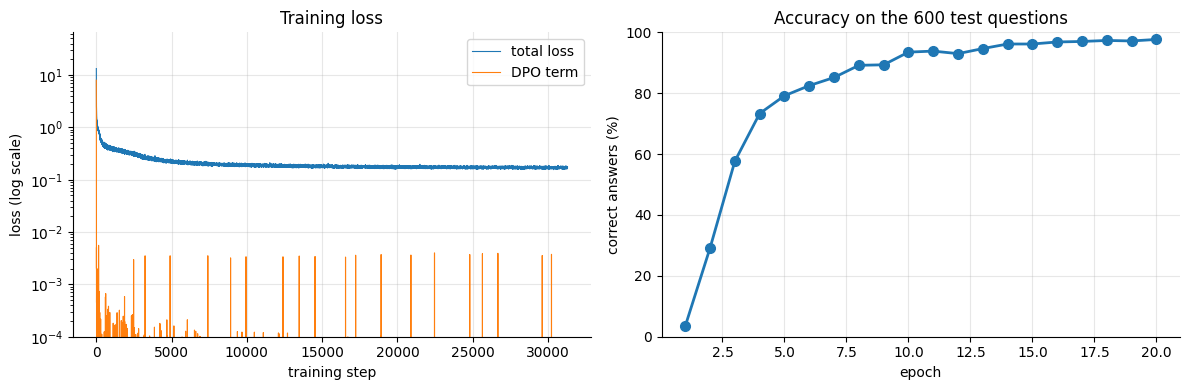

In [12]:
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4))
ax_loss.plot(loss_history, linewidth=0.8, label="total loss")
ax_loss.plot(dpo_loss_history, linewidth=0.8, label="DPO term")
ax_loss.set_yscale("log")
ax_loss.set_ylim(bottom=1e-4)
ax_loss.set_xlabel("training step")
ax_loss.set_ylabel("loss (log scale)")
ax_loss.set_title("Training loss")
ax_loss.legend()


epochs_done = range(1, len(accuracy_history) + 1)
ax_acc.plot(epochs_done, [100 * a for a in accuracy_history],
            linewidth=2, marker="o", markersize=7)
ax_acc.set_xlabel("epoch")
ax_acc.set_ylabel("correct answers (%)")
ax_acc.set_ylim(0, 100)
ax_acc.set_title(f"Accuracy on the {len(test_questions)} test questions")
for ax in (ax_loss, ax_acc):
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## Task 3: Test the fine-tuned model

### Step 8: Begin testing

Here, we test our model on the template's test set. As mentioned earlier, we designed our own test set and base the final analysis on it (next section); we keep the template's test set so that its results can be seen too.

In [13]:
# Load the model checkpoint
ckpt_path = "./dpo.pt"
checkpoint = torch.load(ckpt_path, map_location=device)
gptconf = GPTConfig(**checkpoint['model_args'])
gpt = GPT(gptconf).to(device)
state_dict = checkpoint['model_state_dict']
unwanted_prefix = '_orig_mod.'
for k,v in list(state_dict.items()):
    if k.startswith(unwanted_prefix):
        state_dict[k[len(unwanted_prefix):]] = state_dict.pop(k)
gpt.load_state_dict(state_dict)
# Test those questions provided by the template, and show the result, just for brief demos
gpt.eval()
test_set = ["17+19=?", "3*17=?", "72/4=?", "72-x=34,x=?", "x*11=44,x=?", "3*17=?", "72/4=?", "72-x=34,x=?"]
with torch.no_grad():
    for prompt in test_set:
        prompt_ids = encode(prompt)
        x = torch.tensor([prompt_ids], dtype=torch.long, device=device)
        y, _ = gpt.generate(x, max_new_tokens, temperature=temperature, top_k=top_k)
        reply = decode(y[0].tolist())
        print(reply, "(right)" if reply_is_correct(prompt, reply) else "(wrong)")

17+19=? 17+19 is 36, so the answer is 36. (right)
3*17=? 3*10 is 30, 3*7 is 21, 30+21 is 51, so the answer is 51. (right)
72/4=? 4*10 is 40, 72-40 is 32, 4*8 is 32, so the answer is 18. (right)
72-x=34,x=? x is 72-34, 72-34 is 38, so the answer is 38. (right)
x*11=44,x=? x is 44/11, 11*4 is 44, so the answer is 4. (right)
3*17=? 3*10 is 30, 3*7 is 21, 30+21 is 51, so the answer is 51. (right)
72/4=? 4*10 is 40, 72-40 is 32, 4*8 is 32, so the answer is 18. (right)
72-x=34,x=? x is 72-34, 72-34 is 38, so the answer is 38. (right)


All eight replies are right, and each one is exactly the positive that Task 1 writes for that question, steps included. The three questions that appear twice in the test set got the same reply both times, although the replies are sampled, so the model must be very sure of each next character. **All five questions are among our training questions** (a separate check, not shown), so this small test cannot show whether the model can answer new questions; the 600 test questions below, which were never trained on, are the better measure.

#### Accuracy on the test questions, by question type

Here the final model answers the 600 test questions once more, with the same sampling as above, and we count the correct answers for each question type. A reply is an *exact match* when the whole reply, every step included, is the positive we would have written for that question; a reply can have the right answer without being an exact match. The replies are sampled again, so the total can differ a little from the last epoch in Step 7.

In [14]:
def question_type(question):
    return re.sub(r"\d+", "n", question)  # "x+55=95,x=?" -> "x+n=n,x=?"

_, reply_of = test()

# some metrics if we wish to 
correct_by_type = Counter()
total_by_type = Counter()
exact_num = 0
wrong_replies = []
for question, answer, calculation in test_items:
    reply = reply_of[question]
    kind = question_type(question)
    total_by_type[kind] += 1
    if reply_is_correct(question, reply):
        correct_by_type[kind] += 1
    else:
        wrong_replies.append(reply)
    if reply == write_positive_sample(question, answer, calculation):
        exact_num += 1

        
# Test those on our 600 sample test set
print(f"{'question type':<14} correct")
for kind in total_by_type:
    print(f"{kind:<14} {correct_by_type[kind]:3d} / {total_by_type[kind]}")
total_correct = sum(correct_by_type.values())
final_accuracy = total_correct / len(test_items)
print(f"{'all':<14} {total_correct:3d} / {len(test_items)} = {final_accuracy:.1%}")
print(f"Exact matches (answer and every step): {exact_num} / {len(test_items)}")
print("Some wrong replies:")
for reply in wrong_replies[:8]:
    print(" ", reply)

question type  correct
n+n=?           50 / 50
n-n=?           50 / 50
n*n=?           50 / 50
n/n=?           47 / 50
x+n=n,x=?       50 / 50
n+x=n,x=?       50 / 50
x-n=n,x=?       50 / 50
n-x=n,x=?       50 / 50
x*n=n,x=?       49 / 50
n*x=n,x=?       46 / 50
x/n=n,x=?       50 / 50
n/x=n,x=?       46 / 50
all            588 / 600 = 98.0%
Exact matches (answer and every step): 588 / 600
Some wrong replies:
  700/28=? 28*20 is 560, so the answer is 20.
  888/24=? 24*30 is 720, 888-720 is 48, 24*2 is 48, so the answer is 32.
  6525/75=? 75*80 is 6000, 6525-6000 is 325, 75*5 is 325, so the answer is 85.
  x*80=4720,x=? x is 4720/80, 80*50 is 4000, 4720-4000 is 320, 80*4 is 320, so the answer is 54.
  35*x=1785,x=? x is 1785/35, 35*40 is 1400, 1785-1400 is 385, 35*9 is 385, so the answer is 49.
  8*x=496,x=? x is 496/8, 8*60 is 480, 496-480 is 56, 8*7 is 56, so the answer is 67.
  8*x=408,x=? x is 408/8, 8*50 is 400, 408-400 is 48, 8*6 is 48, so the answer is 56.
  36*x=3024,x=? x is 30

The final model answers **588 of the 600 test questions correctly (98.0%)**:

| Questions | Performance |
|---|---|
| addition and subtraction (6 types) | 300 / 300 |
| the answer is a product (`a*b=?`, `x/a=b,x=?`) | 100 / 100 |
| the answer is a quotient (`a/b=?`, `x*a=b,x=?`, `a*x=b,x=?`, `a/x=b,x=?`) | 188 / 200 |
| all | 588 / 600 |

- **All 12 errors are divisions.** Most of the wrong replies printed above come from a wrong subtraction in the long division (for example `6525-6000 is 325` instead of 525), which then makes the final answer wrong as well.
- **Right answers come with the right steps.** The number of exact matches equals the number of right answers (588), so every right answer was written exactly with our steps.

## Task 4: Explanation and analysis

### Experiments on multiplication questions

Before the full run we tested our ideas on a smaller problem: only the two question types whose answer is a product (`a*b=?` and `x/a=b,x=?`), with 9000 training and 100 test questions each, and 20 epochs. The runs used an earlier version of this notebook's code (with refusals reused from our first attempt as negatives) and are not repeated here. Each accuracy is from 200 test answers, so **differences of a few points are noise**.

| Positive | Extra negatives | SFT weight | After 8 epochs | After 12 | After 20 | Training time |
|---|---|---|---|---|---|---|
| answer first | none | 0.1 | 9.5% | 17.0% | 36.5% | 54 min |
| steps | none | 0.1 | 34.5% | 83.0% | 97.0% | 62 min |
| steps | none | 1 | 67.5% | 90.0% | 100.0% | 63 min |
| steps | the model's own wrong replies | 0.1 | stopped: 0% after 7 epochs | | | |
| steps | the same, cut after the first wrong character | 0.1 | stopped: 0% after 6 epochs | | | |
| steps | the model's own wrong replies | 1 | 54.5% | 79.5% | 97.0% | 135 min |

- **Steps (rows 1 and 2).** Writing the steps out raised the accuracy **from 36.5% to 97%**.
- **SFT weight (rows 2 and 3).** Weight 1 learned faster than 0.1 (67.5% against 34.5% after 8 epochs) and ended at least as high.
- **The model's own wrong answers as negatives (rows 4–6).** After every epoch the model answered 500 training questions, and each wrong reply became an extra negative, a simpler version of Pang et al. (2024). With SFT weight 0.1 training failed, also when both replies were cut after the first wrong character (as in Step-DPO, Lai et al., 2024), and we did not find out why. With SFT weight 1 it worked, but no better than row 3 and twice as slow, so we did not use it.

### Summary

- **Task 1.** We built 100,202 training pairs from 12 question types with numbers from 0 to 100, and kept 600 other questions for testing. The positive works the answer out in short steps and ends with "the answer is N"; the negative is the pretrained model's own reply, almost always a refusal.
- **Task 2.** We fine-tuned with the template's loss, a DPO term plus an SFT term, using SFT weight 1, AdamW, a learning rate falling from 1e-3 towards 1e-4, gradient clipping and 20 epochs. The DPO term is practically 0 from the second epoch on, so most of the learning comes from the SFT term on the worked positives.
- **Task 3.** The final model answers all eight questions of the template's test set correctly, with exactly our steps, and 588 of our 600 test questions (98.0%), against 82.3% for our first attempt. All multiplications are now right; the 12 remaining errors are divisions, often a wrong subtraction inside the long division.
- **What made the difference.** In the experiments on multiplication questions, writing out the steps raised the accuracy from 36.5% to 97%, and SFT weight 1 made the model learn faster. Using the model's own wrong answers as negatives did not help in our setup.
- **What we would try next.** Writing the subtraction in the long division in smaller steps, since that is where most of the remaining errors are.

## References

- A. Karpathy, *nanoGPT*, https://github.com/karpathy/nanoGPT. The course's `model.py` and `configurator.py` are adapted from this repository (for example, `generate` stops at a newline or `.`); we did not change them.
- Course base code, https://github.com/zhouyuan888888/NanoGPT-Math. It provides the pretrained model `sft/gpt.pt`, the character codebook `sft/meta.pkl`, the sample `pos_neg_pairs.json`, and the template notebook: the code of Steps 1–4 (with the changes listed at the top), the skeletons of Steps 7 and 8, and the suggested loss.
- R. Rafailov, A. Sharma, E. Mitchell, S. Ermon, C. D. Manning, C. Finn, "Direct Preference Optimization: Your Language Model is Secretly a Reward Model", NeurIPS 2023, https://arxiv.org/abs/2305.18290.
- N. Lee, K. Sreenivasan, J. D. Lee, K. Lee, D. Papailiopoulos, "Teaching Arithmetic to Small Transformers", ICLR 2024, https://arxiv.org/abs/2307.03381.
- R. Y. Pang, W. Yuan, K. Cho, H. He, S. Sukhbaatar, J. Weston, "Iterative Reasoning Preference Optimization", NeurIPS 2024, https://arxiv.org/abs/2404.19733.
- X. Lai, Z. Tian, Y. Chen, S. Yang, X. Peng, J. Jia, "Step-DPO: Step-wise Preference Optimization for Long-chain Reasoning of LLMs", 2024, https://arxiv.org/abs/2406.18629.
- Libraries: PyTorch (documentation for `torch.optim.AdamW`, `torch.optim.lr_scheduler.CosineAnnealingLR` and `torch.nn.utils.clip_grad_norm_`), tqdm and Matplotlib.

Written for this assignment: the Task 1 cells, the code of Steps 5 and 6, the training code inside the template's Step 7 skeleton and the training curve, the completion of the Step 8 test loop and the evaluation by question type, and all explanations.